# Deskewing: TrOCR baseline comparison

Compare original IAM validation lines against deskewing alone using the existing preprocessing and evaluation pipelines. Lower corpus CER/WER is better; improvement is not assumed. The test split remains reserved for final evaluation. Install requirements-inference.txt in the project environment if needed.

Deskewing searches ±10° at 0.5° increments using an Otsu ink mask and row-projection differences. Only angle estimation uses binarization; the original L/RGB image is rotated with bicubic interpolation, white fill, and an expanded canvas. This can alter scaling after the mandatory TrOCR resize. It does not correct character slant. Defaults are exploratory and must only be tuned on validation data.

In [1]:
import sys
from pathlib import Path
import json
from datetime import datetime, timezone
from importlib.metadata import version

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "src/load_dataset/iam.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.load_dataset.iam import load_iam_dataset, get_sample
from src.preprocessing import Deskew, PreprocessingPipeline
from src.models.trocr import TrOCRRecognizer
from src.evaluation import compare_recognition

In [2]:
SPLIT = "validation"
# Small smoke comparison; set to None for the full validation split.
SAMPLE_INDICES = tuple(range(10))
CHECKPOINT = "microsoft/trocr-base-handwritten"
MODEL_REVISION = "main"  # Wrapper resolves and records the exact commit.
DEVICE = "cpu"
GENERATION = {"max_new_tokens": 128, "num_beams": 1, "do_sample": False}
deskew = Deskew(max_angle=10.0, angle_step=0.5)
pipelines = {
    "baseline": PreprocessingPipeline(),
    "deskew": PreprocessingPipeline((deskew,)),
}
print(json.dumps({k: v.to_config() for k, v in pipelines.items()}, indent=2))

{
  "baseline": {
    "steps": []
  },
  "deskew": {
    "steps": [
      {
        "name": "deskew",
        "enabled": true,
        "max_angle": 10.0,
        "angle_step": 0.5,
        "estimator": "otsu_projection_difference",
        "resampling": "bicubic",
        "expand": true,
        "fill": "white"
      }
    ]
  }
}


In [3]:
assert SPLIT == "validation", "Use validation for development."
dataset = load_iam_dataset(split=SPLIT)
indices = tuple(range(len(dataset))) if SAMPLE_INDICES is None else SAMPLE_INDICES
assert indices and len(set(indices)) == len(indices)
assert all(0 <= i < len(dataset) for i in indices)
samples = [get_sample(dataset, i) for i in indices]
assert all(isinstance(s["ground_truth"], str) and s["ground_truth"].strip() for s in samples)
print("Split size:", len(dataset), "| selected:", len(samples), "| columns:", dataset.column_names)
for s in samples[:3]:
    print(s["id"], s["image"].mode, s["image"].size, repr(s["ground_truth"]))

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Split size: 976 | selected: 10 | columns: ['image', 'text']
sample_0 L (1273, 128) 'It was a splendid interpretation of the'
sample_1 L (1159, 128) 'sympathetic C O . Paul Daneman gave another'
sample_2 L (1318, 128) 'part . The rest of the cast were well chosen ,'


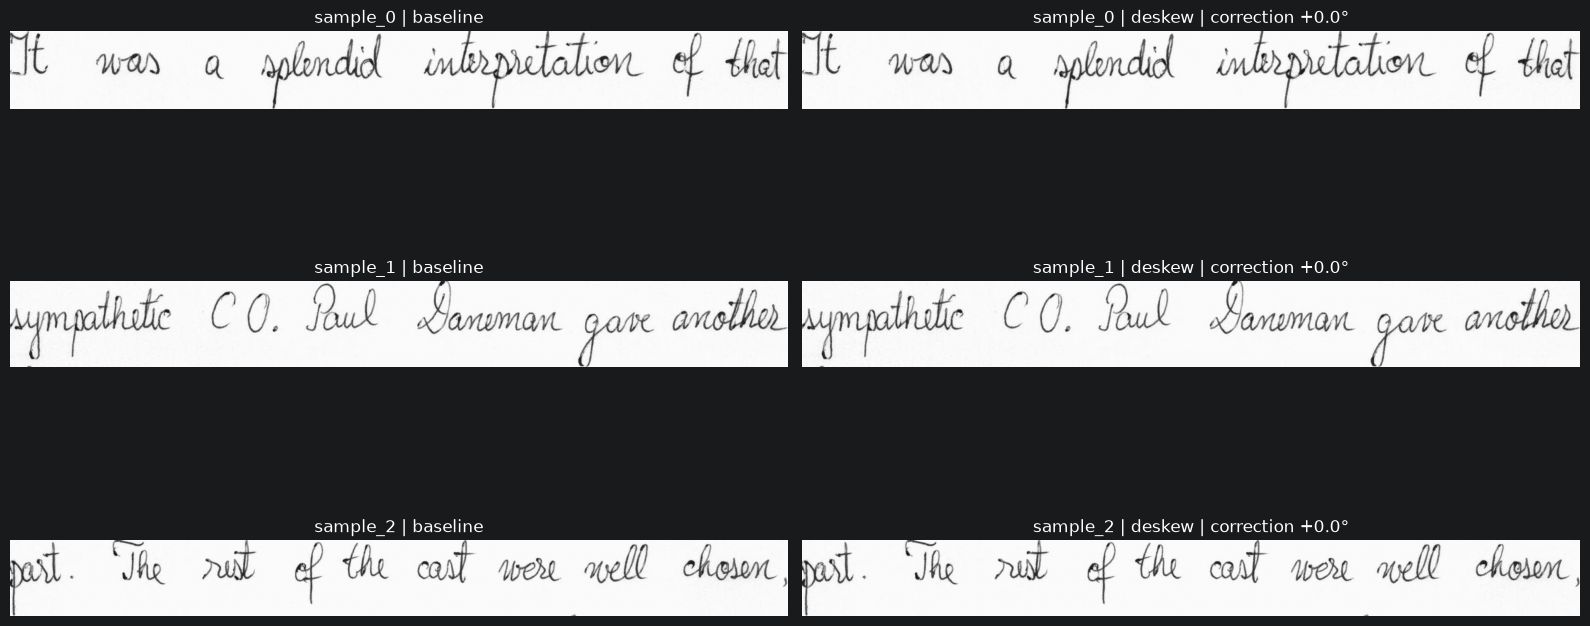

In [5]:
fig, axes = plt.subplots(min(3, len(samples)), 2, figsize=(16, 3 * min(3, len(samples))), squeeze=False)
for row, sample in enumerate(samples[:3]):
    angle = deskew.estimate_angle(sample["image"])
    for col, (name, pipeline) in enumerate(pipelines.items()):
        axes[row, col].imshow(pipeline(sample["image"]), cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{sample['id']} | {name}" + (f" | correction {angle:+.1f}°" if col else ""))
        axes[row, col].axis("off")
fig.tight_layout()
plt.show()

## Controlled recognition evaluation

Load one checkpoint once and reuse it for both configurations. Mandatory RGB conversion and processor transforms run identically after optional preprocessing. Text normalization collapses whitespace and strips edges while retaining case and punctuation. Corpus metrics aggregate edit counts over all selected references, rather than averaging line rates. Ten samples are a smoke comparison, not evidence of general effectiveness. Model loading requires Hugging Face access; CPU inference may take several minutes.

W1101 16:17:36.378000 94164 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


baseline: 1/10
baseline: 2/10
baseline: 3/10
baseline: 4/10
baseline: 5/10
baseline: 6/10
baseline: 7/10
baseline: 8/10
baseline: 9/10
baseline: 10/10
deskew: 1/10
deskew: 2/10
deskew: 3/10
deskew: 4/10
deskew: 5/10
deskew: 6/10
deskew: 7/10
deskew: 8/10
deskew: 9/10
deskew: 10/10


,sample_count,cer,wer,inference_seconds,cer_change_from_baseline,wer_change_from_baseline
configuration,,,,,,
baseline,10,0.030691,0.121951,7.802637,0.0,0.0
deskew,10,0.030691,0.121951,7.493838,0.0,0.0


,sample_id,configuration,ground_truth,prediction,cer,wer
0,sample_0,baseline,It was a splendid interpretation of the,It was a splendid interpretation of that,0.051282,0.142857
1,sample_1,baseline,sympathetic C O . Paul Daneman gave another,sympathetic CO . Paul Daneman gave another,0.023256,0.250000
2,sample_2,baseline,"part . The rest of the cast were well chosen ,","part . The rest of the cast were well chosen ,",0.000000,0.000000
3,sample_3,baseline,with James Maxwell making a fine job of the,with James Maxwell making a fine job of the,0.000000,0.000000
4,sample_4,baseline,""" The Little Key . """,""" The Little Key . """,0.000000,0.000000
5,sample_5,baseline,first-class performance last night as a,first-class performance last night as a,0.000000,0.000000
6,sample_6,baseline,wartime naval officer in the B B C's,wartime naval officer in the BBC's,0.055556,0.375000
7,sample_7,baseline,the imagination which asked the viewer to,the imagination which asked the viewer to,0.000000,0.000000
8,sample_8,baseline,""" Britain - Blood , Sweat , and Tears ... Plus","' Britain - Blood ' , Tweet , and Tears ... . ...",0.152174,0.363636
9,sample_9,baseline,The play was no more than a figment of,The play was no more than a figment of,0.000000,0.000000


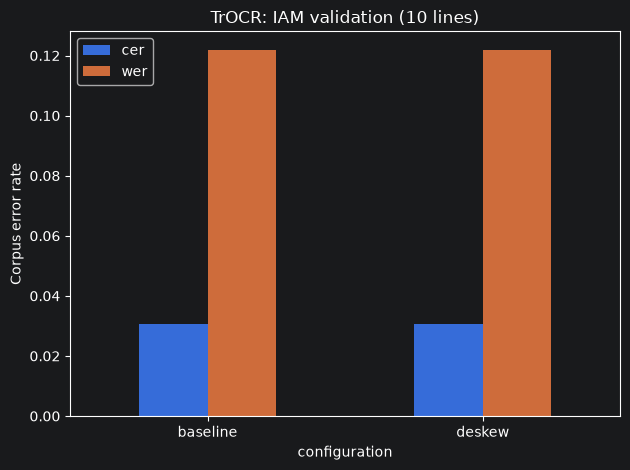

In [4]:
model = TrOCRRecognizer(checkpoint=CHECKPOINT, revision=MODEL_REVISION,
                        device=DEVICE, generation_kwargs=GENERATION)
rows, summaries = compare_recognition(samples, model, pipelines)
predictions = pd.DataFrame(rows)
summary = pd.DataFrame(summaries).set_index("configuration")
for metric in ("cer", "wer"):
    summary[f"{metric}_change_from_baseline"] = summary[metric] - summary.loc["baseline", metric]
display(summary)
display(predictions[["sample_id", "configuration", "ground_truth", "prediction", "cer", "wer"]])
summary[["cer", "wer"]].plot.bar(rot=0, ylabel="Corpus error rate", title=f"TrOCR: IAM {SPLIT} ({len(samples)} lines)")
plt.tight_layout()
plt.show()

In [6]:
metadata = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": "Teklia/IAM-line", "split": SPLIT, "sample_indices": list(indices),
    "dataset_fingerprint": dataset._fingerprint,
    "dataset_revision": "not pinned by existing loader; fingerprint recorded",
    "model": model.to_config(),
    "preprocessing": {k: v.to_config() for k, v in pipelines.items()},
    "normalization": "collapse whitespace; strip edges; retain case and punctuation",
    "sampling": "fixed ordered indices; no random sampling",
    "versions": {p: version(p) for p in ("torch", "transformers", "huggingface-hub",
        "jiwer", "numpy", "Pillow", "opencv-python-headless", "datasets", "pandas", "matplotlib")},
}
# A fresh directory prevents overwriting earlier experiments.
run_dir = PROJECT_ROOT / "results" / ("deskew_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
run_dir.mkdir(parents=True, exist_ok=False)
predictions.to_csv(run_dir / "predictions.csv", index=False)
summary.to_csv(run_dir / "summary.csv")
(run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved:", run_dir)

Saved: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/deskew_20261101T211759471636Z


Inspect examples that improve and worsen before drawing conclusions. Negative metric changes indicate improvement. Timing columns are descriptive, exclude model loading, and can be affected by warm-up and configuration order. For reproducible repeats, reuse the recorded model commit and dataset fingerprint; the current dataset loader does not pin a revision. Run the full validation split with fixed settings before a final held-out test evaluation.